In [2]:
import os
import re
import kagglehub
import pandas as pd
from sklearn.model_selection import train_test_split

path = kagglehub.dataset_download("snap/amazon-fine-food-reviews")
df_full = pd.read_csv(os.path.join(path, "Reviews.csv"))
df = df_full.sample(n=50000, random_state=42)

df = df.dropna(subset=["Text", "Score"]).copy()
df = df.drop_duplicates(subset=["Text"]).copy()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["Clean_Text"] = df["Text"].apply(clean_text)
df = df[df["Clean_Text"] != ""].copy()
df["Sentiment"] = (df["Score"] >= 4).astype(int)

train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["Sentiment"]
)

train_df.to_csv("alpha_train.csv", index=False)
test_df.to_csv("alpha_test.csv", index=False)

print("Saved alpha_train.csv:", len(train_df), "| alpha_test.csv:", len(test_df))

/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Saved alpha_train.csv: 37054 | alpha_test.csv: 9264


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
import time

# Load the train and test data
train_text = train_df["Clean_Text"].fillna("").astype(str)
test_text = test_df["Clean_Text"].fillna("").astype(str)
train_labels = train_df["Sentiment"]
test_labels = test_df["Sentiment"]

# Vectorize the text data using TF-IDF
vectorizer = TfidfVectorizer(max_features=5000)
start_time = time.perf_counter()
train_tfidf = vectorizer.fit_transform(train_text)
test_tfidf = vectorizer.transform(test_text)

# Train a logistic regression model
lr = LogisticRegression(max_iter=1000)
lr.fit(train_tfidf, train_labels)
lr_train_time = time.perf_counter() - start_time
print(f"Logistic Regression training time: {lr_train_time:.4f}s")
test_predictions = lr.predict(test_tfidf)

# Evaluate the model
print("Accuracy:", accuracy_score(test_labels, test_predictions))
print("\nClassification Report:\n", classification_report(test_labels, test_predictions))

Logistic Regression training time: 1.4829s
Accuracy: 0.8742443868739206

Classification Report:
               precision    recall  f1-score   support

           0       0.79      0.58      0.67      2019
           1       0.89      0.96      0.92      7245

    accuracy                           0.87      9264
   macro avg       0.84      0.77      0.79      9264
weighted avg       0.87      0.87      0.87      9264



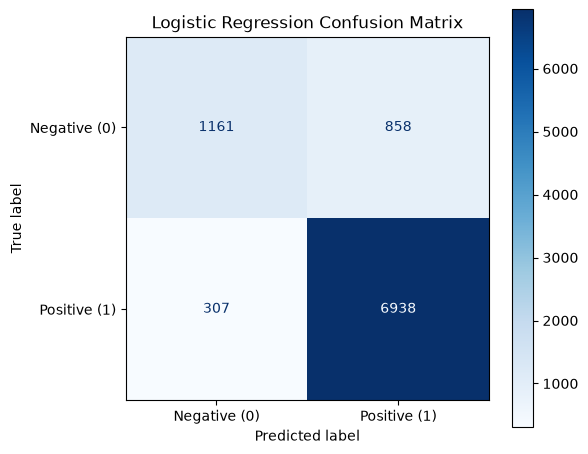

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_estimator(
    lr,
    test_tfidf,  
    test_labels,
    display_labels=["Negative (0)", "Positive (1)"],
    cmap="Blues",
    values_format="d",  
    ax=ax,
)

ax.set_title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()